# VRDet: Stage 01: Data Fetch and Cleaning

Where the data comes from and every cleaning step applied before features are built.

| Series | Source | Use |
|---|---|---|
| NIFTY 50, 15-minute and daily candles | Angel One SmartAPI (`getCandleData`) | the asset whose regime is classified; daily candles are the official reference for validation |
| India VIX, 15-minute and daily | Angel One SmartAPI | implied-volatility inputs |
| USD/INR, Brent crude (daily) | Yahoo Finance (`yfinance`) | cross-asset context, used as *previous-day* values only (causal) |

The production archive is written by `scripts/fetch_data.py` to `data/raw/`. This notebook repeats the download
step by step (into memory, the archive is not overwritten unless `SAVE = True`) and checks that it reproduces
the archive, then walks through the cleaning: session filter, OHLC consistency, completeness, validation against
the official daily candles, the known vendor defects, and the per-stock level alignment used by the Stock Lab.

Credentials come from `.env` (gitignored) and are never printed.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = REPO / 'data' / 'processed'      # raw data: <repo>/data/raw (or set VRDET_DATA)
FIG = OUT / 'figures'

sys.path.insert(0, str(REPO / 'src'))
for m in [m for m in sys.modules if m == 'vrdet' or m.startswith('vrdet.')]:
    del sys.modules[m]  # forget any previously imported (stale) vrdet
FIG.mkdir(parents=True, exist_ok=True)
print('repo:', REPO)

repo: C:\dev\vrdet


In [2]:
import contextlib, io, logging, time
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vrdet.angel import TOKENS, clean_intraday, load_env, login, request_candles, to_frame
from vrdet.data import load_raw
from vrdet.quality import session_report, to_daily, yearly_summary

pd.set_option('display.width', 200)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True, 'font.size': 9.5})
REGIME_COLORS = ['#2e9e5b', '#d9a400', '#d93636']      # Quiet, Normal, Chaotic (same as the dashboard)
HIGHLIGHT = {'production': '#2a78d6', 'benchmark': '#eb6834'}   # categorical slots 1-2
GREY = '#9aa3ad'

FETCH = True    # download from Angel One (needs .env); False = demonstrate on the archive in data/raw only
SAVE = False    # True overwrites data/raw with this download (what scripts/fetch_data.py does)
FLOOR = datetime(2015, 1, 1)

## 1. Log in to Angel One SmartAPI

Login needs the API key, client code, PIN and a TOTP generated from the TOTP secret (`pyotp`). The session is
valid for the day. Output is suppressed so the account name does not end up in the notebook.

In [3]:
if FETCH:
    import logzero
    logzero.loglevel(logging.WARNING)                  # SmartAPI's own INFO logging
    load_env()
    with contextlib.redirect_stdout(io.StringIO()):     # keep the account name out of the notebook
        smart = login()
    print('logged in')

logged in

## 2. One request

`getCandleData` returns rows `[timestamp, open, high, low, close, volume]` for one instrument token, interval and
date range. Index candles have no volume (0). Timestamps carry the IST offset; `to_frame` turns them into a
tz-aware (Asia/Kolkata) index. Example: 7 April 2025, the US-tariff sell-off.

In [4]:
if FETCH:
    rows = request_candles(smart, TOKENS['NIFTY'], 'FIFTEEN_MINUTE', datetime(2025, 4, 7, 9, 0), datetime(2025, 4, 7, 15, 30))
    print(len(rows), 'candles; first row as returned:', rows[0])
    day = to_frame(rows)
    display(day.head())

25

candles; first row as returned:

['2025-04-07T09:15:00+05:30', 21758.4, 22102.95, 21743.65, 22041.85, 0]

,open,high,low,close,volume
timestamp,,,,,
2025-04-07 09:15:00+05:30,21758.40,22102.95,21743.65,22041.85,0
2025-04-07 09:30:00+05:30,22042.35,22190.00,21977.05,22021.70,0
2025-04-07 09:45:00+05:30,22023.35,22050.65,21959.75,21963.25,0
2025-04-07 10:00:00+05:30,21960.55,22011.05,21911.05,21918.15,0
2025-04-07 10:15:00+05:30,21916.00,22005.65,21898.30,22005.15,0


## 3. Full history in chunks

SmartAPI limits the date range per request (200 days for 15-minute candles, 2,000 for daily) and the request
rate, so history is fetched backwards in chunks with a short pause between requests. Each request is retried
with back-off (`request_candles`). Angel One's 15-minute index history starts in 2015.

In [5]:
MAX_DAYS = {'FIFTEEN_MINUTE': 200, 'ONE_DAY': 2000}


def fetch_history(name, interval, floor=FLOOR):
    token, step = TOKENS[name], timedelta(days=MAX_DAYS[interval] - 1)
    end, rows, n, t0 = datetime.now(), [], 0, time.perf_counter()
    while end > floor:
        start = max(end - step, floor)
        rows += request_candles(smart, token, interval, start.replace(hour=9, minute=0), end.replace(hour=15, minute=30))
        n += 1
        end = start - timedelta(days=1)
        time.sleep(0.4)                                   # stay under the rate limit
    df = to_frame(rows)
    print(f'{name:<8} {interval:<14} {n:>3} requests, {len(df):>7,} candles, '
          f'{df.index[0]:%Y-%m-%d} -> {df.index[-1]:%Y-%m-%d} ({time.perf_counter() - t0:.0f}s)')
    return df


raw = load_raw()     # the archive in data/raw (written by scripts/fetch_data.py)
if FETCH:
    fresh = {f'{name}_{tag}': fetch_history(name, interval)
             for name in TOKENS for interval, tag in (('FIFTEEN_MINUTE', '15m'), ('ONE_DAY', '1d'))}
else:
    fresh = {k: raw[k] for k in ('NIFTY_15m', 'NIFTY_1d', 'INDIAVIX_15m', 'INDIAVIX_1d')}

NIFTY    FIFTEEN_MINUTE  22 requests,  72,945 candles, 2015-01-01 -> 2026-10-30 (18s)

NIFTY    ONE_DAY          3 requests,   2,916 candles, 2015-01-02 -> 2026-10-30 (2s)

INDIAVIX FIFTEEN_MINUTE  22 requests,  67,283 candles, 2015-12-01 -> 2026-10-30 (17s)

INDIAVIX ONE_DAY          3 requests,   2,926 candles, 2015-01-02 -> 2026-10-30 (2s)

### Does the download reproduce the archive?

On the overlapping candles, prices should be identical. Differences would mean the vendor revised history (worth
knowing before trusting any backtest).

In [6]:
def naive_dates(df):
    idx = pd.DatetimeIndex(df.index)
    out = df.copy()
    out.index = (idx.tz_localize(None) if idx.tz is not None else idx).normalize()
    return out


rows = []
for key, new in fresh.items():
    old = raw[key]
    if key.endswith('_1d'):
        new = naive_dates(new)
    common = new.index.intersection(old.index)
    cols = ['open', 'high', 'low', 'close']
    rel = (new.loc[common, cols] / old.loc[common, cols] - 1).abs().max(axis=1)
    rows.append({'series': key, 'downloaded': len(new), 'archive': len(old), 'overlap': len(common),
                 'differing_candles': int((rel > 1e-9).sum()), 'max_rel_diff': rel.max(),
                 'archive_end': old.index[-1], 'download_end': new.index[-1]})
pd.DataFrame(rows).set_index('series')

,downloaded,archive,overlap,differing_candles,max_rel_diff,archive_end,download_end
series,,,,,,,
NIFTY_15m,72945,72646,72646,1,0.011109,2026-10-29 15:15:00+05:30,2026-10-30 15:15:00+05:30
NIFTY_1d,2916,4132,2914,0,0.000000,2026-10-29 00:00:00,2026-10-30 00:00:00
INDIAVIX_15m,67283,67090,67090,0,0.000000,2026-10-29 15:15:00+05:30,2026-10-30 15:15:00+05:30
INDIAVIX_1d,2926,4168,2924,0,0.000000,2026-10-29 00:00:00,2026-10-30 00:00:00


### Cross-asset series (Yahoo Finance)

Daily USD/INR and Brent. They trade on different calendars and time zones, so features only ever use the value
of the *previous* NIFTY session (`features._prev_day_lookup`), never the same day.

In [7]:
import warnings
import yfinance as yf
warnings.filterwarnings('ignore', module='yfinance')    # pandas deprecation notices from inside yfinance

yf_series = {}
for name, ticker in {'USDINR': 'USDINR=X', 'BRENT': 'BZ=F'}.items():
    df = yf.download(ticker, start='2015-01-01', interval='1d', auto_adjust=False, progress=False)
    df.columns = [c[0].lower() if isinstance(c, tuple) else c.lower() for c in df.columns]
    yf_series[name] = df
    print(f'{name:<7} {len(df):,} daily rows, {df.index[0].date()} -> {df.index[-1].date()}, '
          f'missing closes: {df["close"].isna().sum()}')

USDINR  3,080 daily rows, 2015-01-01 -> 2026-10-31, missing closes: 0

BRENT   2,976 daily rows, 2015-01-02 -> 2026-10-30, missing closes: 0

## 4. Cleaning

### 4.1 Regular session and OHLC consistency

`clean_intraday` keeps weekday bars between 09:15 and 15:30 IST and drops candles whose high/low do not contain
their open/close. Bars outside the regular session come from special sessions (Muhurat trading on Diwali,
exchange mock/special sessions on weekends), which have different liquidity and no place in a 15-minute model.

In [8]:
nifty = clean_intraday(fresh['NIFTY_15m'])
vix = clean_intraday(fresh['INDIAVIX_15m'])
print(f'NIFTY {len(fresh["NIFTY_15m"]):,} -> {len(nifty):,} candles; India VIX {len(fresh["INDIAVIX_15m"]):,} -> {len(vix):,}')

  dropping 200 bars outside the regular session on 20 dates (special/extended sessions): 2015-02-28, 2015-11-11, 2016-10-28, 2016-10-30, 2017-04-28, 2017-10-19, 2018-11-07, 2019-10-27, 2020-02-01, 2020-11-14 ...

  dropping 74 bars with inconsistent OHLC

  dropping 162 bars outside the regular session on 17 dates (special/extended sessions): 2016-10-28, 2016-10-30, 2017-04-28, 2017-10-19, 2018-11-07, 2019-10-27, 2020-02-01, 2020-11-14, 2021-02-24, 2021-11-04 ...

  dropping 6 bars with inconsistent OHLC

NIFTY 72,945 -> 72,671 candles; India VIX 67,283 -> 67,115

### 4.2 Completeness

A full session has 25 bars (09:15 ... 15:15). Shorter sessions are half days, the Muhurat session, or gaps in
the vendor feed.

In [9]:
per_day = nifty.groupby(nifty.index.date).size()
print(per_day.value_counts().sort_index(ascending=False).rename('sessions').to_frame().T.to_string())
short = per_day[per_day < 25]
print(f'\n{len(short)} of {len(per_day):,} sessions have fewer than 25 bars; the shortest:')
short.sort_values().head(8).rename('bars').to_frame().T

            25  24  23  22  21  20  18  17  13  8   4 
sessions  2890   5   2   1   2   3   4   2   1   1   1


22 of 2,912 sessions have fewer than 25 bars; the shortest:

,2021-02-24,2025-10-21,2017-07-10,2017-08-04,2018-03-23,2020-06-04,2020-03-13,2017-07-26
bars,4,8,13,17,17,18,18,18


### 4.3 Validation against the official daily candles

Each intraday session is rebuilt into a daily candle and compared with the official daily candle
(`quality.session_report`). A session is **valid** when it is not partial (at least 13 bars), not flat, and its
intraday high, low and close reproduce at least 2 of the 3 official values within 1%. (All three is too
strict: the official NIFTY close is a 30-minute weighted average, not the last trade.) Invalid sessions are
masked before features are computed, so a corrupt day can never look like a volatility shock.

In [10]:
reports = {}
for name, intra in (('NIFTY', nifty), ('INDIAVIX', vix)):
    rep = session_report(intra, naive_dates(fresh[f'{name}_1d']))
    reports[name] = rep
    print(f'{name}: {(~rep.valid).sum()} invalid of {len(rep):,} sessions')
    display(yearly_summary(rep))

NIFTY: 2 invalid of 2,912 sessions

,sessions,valid_%,flat,partial,missing_bars,zero_range_bars,high_match_%,low_match_%,close_match_%,median_close_err_%
timestamp,,,,,,,,,,
2015,244,100.0,0,0,0,0,99.2,99.2,99.2,0.000
2016,246,100.0,0,0,0,0,100.0,100.0,100.0,0.000
2017,247,100.0,0,0,47,0,95.1,95.1,95.1,0.000
2018,245,100.0,0,0,13,0,100.0,100.0,100.0,0.000
2019,244,100.0,0,0,0,0,100.0,100.0,100.0,0.000
2020,250,100.0,0,0,31,1,99.6,100.0,100.0,0.000
2021,247,99.6,0,1,21,0,99.2,99.6,99.2,0.000
2022,247,100.0,0,0,0,1,100.0,100.0,100.0,0.000
2023,245,100.0,0,0,0,0,100.0,100.0,100.0,0.000


INDIAVIX: 207 invalid of 2,688 sessions

,sessions,valid_%,flat,partial,missing_bars,zero_range_bars,high_match_%,low_match_%,close_match_%,median_close_err_%
timestamp,,,,,,,,,,
2015,22,0.0,21,0,0,459,0.0,0.0,0.0,99.008
2016,246,27.6,161,0,0,3349,29.3,27.6,28.0,98.989
2017,247,99.6,0,1,14,0,100.0,88.7,100.0,0.000
2018,245,100.0,0,0,2,0,100.0,97.1,99.6,0.000
2019,244,100.0,0,0,1,0,100.0,98.8,96.3,0.000
2020,250,99.6,0,0,8,2,99.6,99.6,100.0,0.000
2021,245,99.2,0,1,28,17,99.2,97.6,98.4,0.000
2022,247,99.2,0,0,11,0,99.2,93.9,100.0,0.000
2023,245,100.0,0,0,3,0,100.0,100.0,95.9,0.000


In [11]:
bad = reports['INDIAVIX'][~reports['INDIAVIX'].valid]
print('India VIX invalid sessions by month:')
print(bad.groupby(bad.index.to_period('M')).size().to_string())

India VIX invalid sessions by month:

timestamp
2015-12    22
2016-01    20
2016-02    21
2016-03    20
2016-04    18
2016-05    22
2016-06    22
2016-07    20
2016-08    22
2016-09    13
2017-07     1
2020-01     1
2021-02     1
2021-03     1
2022-08     2
2025-10     1
Freq: M

### 4.4 A vendor defect: India VIX 2015-12 to 2016-09

The ratio of the intraday close to the official daily close should be about 1. For roughly ten months Angel One's
intraday India VIX is on a different scale (about 1/100), which would create absurd VIX features. Validation catches
every one of these sessions.

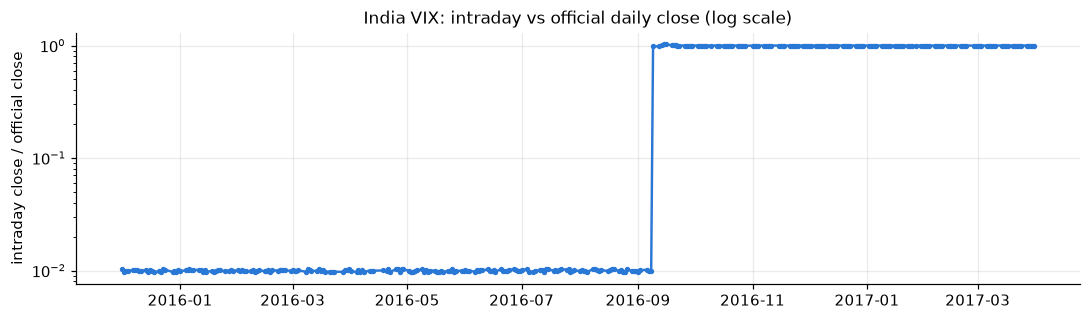

In [12]:
s = to_daily(vix)['close'] / naive_dates(fresh['INDIAVIX_1d'])['close'].reindex(to_daily(vix).index)
win = s['2015-06-01':'2017-03-31']
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(win.index, win.values, color='#2a78d6', lw=1.6, marker='o', ms=2.5)
ax.set_yscale('log')
ax.set_ylabel('intraday close / official close')
ax.set_title('India VIX: intraday vs official daily close (log scale)')
fig.tight_layout(); fig.savefig(FIG / 'data_vix_defect.png', dpi=130); plt.show()

### 4.5 Zero-range closing candles (since August 2026)

Since August 2026 the vendor sends the 15:15 candle as a single print (open = high = low = close, the closing
price). Its range carries no information, so the range-based features treat it as missing instead of "very
quiet" (`features.build_features`). Live sessions therefore have 24 scored bars.

In [13]:
recent = nifty[nifty.index >= nifty.index[-1] - pd.DateOffset(months=8)]
tab = pd.DataFrame({'month': recent.index.strftime('%Y-%m'),
                    'bar': np.where(recent.index.strftime('%H:%M') == '15:15', '15:15 bar', 'other bars'),
                    'zero_range': (recent['high'] == recent['low']).to_numpy()})
print('share of zero-range candles')
tab.groupby(['month', 'bar'])['zero_range'].mean().unstack().round(3)

share of zero-range candles

bar,15:15 bar,other bars
month,,
2026-03,0.000,0.0
2026-04,0.000,0.0
2026-05,0.000,0.0
2026-06,0.000,0.0
2026-07,0.000,0.0
2026-08,0.476,0.0
2026-09,1.000,0.0
2026-10,1.000,0.0


### 4.6 Stocks: intraday and daily archives adjusted differently

For single stocks (Stock Lab), Angel One sometimes applies a corporate-action adjustment to the daily series but
not to the intraday one. RELIANCE intraday before 2022-01-05 sits at about ×1.10 the daily series, which shows
up as a fake −9.5% overnight crash and fails validation for 40% of sessions. `stocks.align_to_daily` estimates
the factor per session as an 11-session rolling median of daily close / intraday close and rescales intraday
prices where it differs from 1 by more than 0.5%. The features are scale-free within a session, so this is a
pure level correction. (The small wiggles that remain are expected: the official close is a closing-auction /
weighted price, not the last 15-minute close.) Uses the Stock Lab cache in `data/stocks/` (created by a Stock Lab or
`scripts/train_stock.py` run).

  intraday level x0.9079 on 782 sessions (2018-10-31 -> 2022-01-04) to match the official daily series (vendor adjusted them differently)

  intraday level x0.9929 on 13 sessions (2023-07-03 -> 2023-07-19) to match the official daily series (vendor adjusted them differently)

valid sessions: before 60.3%, after 99.9%

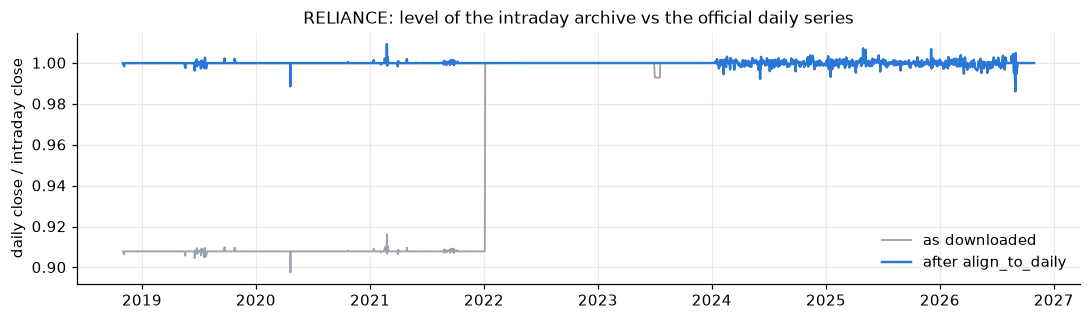

In [14]:
from vrdet.stocks import DATA_DIR, _naive_daily, adjust_corporate_actions, align_to_daily

path = DATA_DIR / 'RELIANCE_15m.parquet'
if path.exists():
    intra, daily = pd.read_parquet(path), pd.read_parquet(DATA_DIR / 'RELIANCE_1d.parquet')
    fixed = align_to_daily(intra, daily, print)
    fixed, _ = adjust_corporate_actions(fixed, daily, print)
    before, after = (session_report(x, _naive_daily(daily)) for x in (intra, fixed))
    print(f'valid sessions: before {before.valid.mean():.1%}, after {after.valid.mean():.1%}')

    ratio = lambda x: _naive_daily(daily)['close'].reindex(to_daily(x).index) / to_daily(x)['close']
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(ratio(intra).index, ratio(intra).values, color=GREY, lw=1.2, label='as downloaded')
    ax.plot(ratio(fixed).index, ratio(fixed).values, color='#2a78d6', lw=1.6, label='after align_to_daily')
    ax.set_ylabel('daily close / intraday close'); ax.legend(frameon=False)
    ax.set_title('RELIANCE: level of the intraday archive vs the official daily series')
    fig.tight_layout(); fig.savefig(FIG / 'data_reliance_alignment.png', dpi=130); plt.show()
else:
    print('No RELIANCE cache yet: run `python scripts/train_stock.py RELIANCE` first.')

## 5. Save (optional) and what goes downstream

With `SAVE = True` the download replaces the archive in `data/raw/`, exactly as `scripts/fetch_data.py` does
(including the per-session validation reports). Feature building (Stage 02) reads the archive with
`vrdet.data.load_raw()` and masks invalid sessions itself.

In [15]:
if SAVE and FETCH:
    out = REPO / 'data' / 'raw'
    for key, df in fresh.items():
        (clean_intraday(df, verbose=False) if key.endswith('_15m') else df).to_parquet(out / f'{key}.parquet')
    for name, df in yf_series.items():
        df.to_parquet(out / f'{name}_1d.parquet')
    print('archive updated:', out)

pd.DataFrame([{'series': k, 'rows': len(v), 'from': v.index[0], 'to': v.index[-1]} for k, v in load_raw().items()]).set_index('series')

,rows,from,to
series,,,
BRENT_1d,4201,2010-01-04 00:00:00,2026-10-29 00:00:00
INDIAVIX_15m,67090,2015-12-01 09:15:00+05:30,2026-10-29 15:15:00+05:30
INDIAVIX_1d,4168,2010-01-04 00:00:00,2026-10-29 00:00:00
INDIAVIX_5m,201244,2015-12-01 09:15:00+05:30,2026-10-29 15:25:00+05:30
NIFTY_15m,72646,2015-01-01 09:15:00+05:30,2026-10-29 15:15:00+05:30
NIFTY_1d,4132,2010-01-04 00:00:00,2026-10-29 00:00:00
NIFTY_5m,217914,2015-01-01 09:15:00+05:30,2026-10-29 15:25:00+05:30
NIFTY_YF_1d,4132,2010-01-04 00:00:00,2026-10-29 00:00:00
USDINR_1d,4380,2010-01-01 00:00:00,2026-10-29 00:00:00


## Takeaways (run of 31 Oct 2026)

* **Reproducible:** an independent download reproduces the archive: daily series and India VIX are identical
  candle for candle, and 1 of 72,646 NIFTY 15-minute candles differs (by 1.1%, a vendor revision).
* **Small, explainable cleaning:** 200 NIFTY candles from 20 special sessions (Muhurat trading, weekend sessions)
  and 74 candles with inconsistent OHLC are removed. 2,890 of 2,912 sessions are complete (25 bars).
* **Validation finds real defects, not noise:** NIFTY has 2 invalid sessions out of 2,912. India VIX has 207, of
  which 200 are the December 2015 – September 2016 scale defect (intraday VIX at 1/100 of the official value).
  Without validation these would read as the largest volatility shocks in the data.
* **The vendor feed changes:** since August 2026 the closing candle is a single print. It is treated as
  missing, not as a calm bar.
* **Stocks need one more step:** RELIANCE's intraday archive was at ×1.10 the official daily series for 782
  sessions; rescaling took valid sessions from 60.3% to 99.9%. Before this fix every model called RELIANCE
  Chaotic.